## Load Library

In [167]:
import numpy as np

## Functions

In [168]:
def check_data_quality(df):
    report = {}

    # 1. Check for NaN values
    nan_report = df.isna().sum()
    report['missing_values'] = nan_report[nan_report > 0].to_dict()

    # 2. Check numeric ranges
    numeric_checks = {}

    if 'age' in df.columns:
        numeric_checks['age_out_of_range'] = df[(df['age'] < 0) | (df['age'] > 64)].shape[0]

    if 'bmi' in df.columns:
        numeric_checks['bmi_out_of_range'] = df[(df['bmi'] < 10) | (df['bmi'] > 60)].shape[0]

    if 'children' in df.columns:
        numeric_checks['children_out_of_range'] = df[df['children'] < 0].shape[0]

    report['numeric_issues'] = {k: v for k, v in numeric_checks.items() if v > 0}

    # 3. Check categorical validity
    cat_checks = {}

    if 'sex' in df.columns:
        valid_sex = {'male', 'female', 'unknown'}
        cat_checks['invalid_sex'] = df[~df['sex'].isin(valid_sex)].shape[0]

    if 'smoker' in df.columns:
        valid_smoker = {'yes', 'no', 'unknown'}
        cat_checks['invalid_smoker'] = df[~df['smoker'].isin(valid_smoker)].shape[0]

    if 'region' in df.columns:
        valid_region = {'southeast', 'southwest', 'northwest', 'northeast', 'unknown'}
        cat_checks['invalid_region'] = df[~df['region'].isin(valid_region)].shape[0]

    report['categorical_issues'] = {k: v for k, v in cat_checks.items() if v > 0}

    # 4. Check engineered features
    engineered_checks = {}

    if 'age_bucket' in df.columns:
        engineered_checks['age_bucket_missing'] = df['age_bucket'].isna().sum()

    if 'region_bucket' in df.columns:
        engineered_checks['region_bucket_missing'] = df['region_bucket'].isna().sum()

    if 'is_male' in df.columns:
        engineered_checks['is_male_missing'] = df['is_male'].isna().sum()

    if 'is_smoker' in df.columns:
        engineered_checks['is_smoker_missing'] = df['is_smoker'].isna().sum()

    report['engineered_feature_issues'] = {k: v for k, v in engineered_checks.items() if v > 0}

    # 5. Final summary
    needs_cleaning = any(len(section) > 0 for section in report.values())
    report['needs_cleaning'] = needs_cleaning

    return report


## Data Ingestation


In [169]:
!pip install -U datasets fsspec

from datasets import load_dataset
import pandas as pd

# Load the dataset
ds = load_dataset("mgchavez/insurance-charge-mlops-logs")

# Convert to pandas DataFrame (assuming the 'train' split, or showing available splits)
print("Dataset splits:", ds.keys())

# Convert the first split (usually 'train') to a pandas DataFrame
split_name = list(ds.keys())[0]
df = ds[split_name].to_pandas()

# Display the DataFrame info and first few rows
print(f"\nConverted split '{split_name}' to DataFrame:")
print(df.info())
df.head()

  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
Dataset splits: dict_keys(['train'])

Converted split 'train' to DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2704 entries, 0 to 2703
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   age         2704 non-null   int64  
 1   bmi         2704 non-null   float64
 2   children    2704 non-null   int64  
 3   sex         2703 non-null   object 
 4   smoker      2703 non-null   object 
 5   region      2702 non-null   object 
 6   prediction  2704 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 148.0+ KB
None


,age,bmi,children,sex,smoker,region,prediction
0,20,30.0,0,male,no,southeast,2644.615637
1,20,30.0,0,male,no,southwest,2492.680579
2,20,30.0,0,male,no,southwest,2492.680579
3,20,30.0,0,male,no,southwest,2492.680579
4,20,30.0,0,male,no,southwest,2492.680579


In [170]:
df.head()

,age,bmi,children,sex,smoker,region,prediction
0,20,30.0,0,male,no,southeast,2644.615637
1,20,30.0,0,male,no,southwest,2492.680579
2,20,30.0,0,male,no,southwest,2492.680579
3,20,30.0,0,male,no,southwest,2492.680579
4,20,30.0,0,male,no,southwest,2492.680579


## Data Cleaning

In [171]:
# Handle missing numeric values (simple strategy)
df['age'] = df['age'].fillna(df['age'].median())
df['bmi'] = df['bmi'].fillna(df['bmi'].median())
df['children'] = df['children'].fillna(0)
df['prediction'] = df['prediction'].fillna(df['prediction'].median())

In [172]:
# Clip unrealistic values
df['age'] = df['age'].clip(0, 64)
df['bmi'] = df['bmi'].clip(10, 60)   # typical safe BMI range
df['children'] = df['children'].clip(0, 10)

In [173]:
#df['sex'].unique() # ['male', None, 'female', 'yes']
valid_sex = ['male', 'female']

df['sex'] = df['sex'].where(df['sex'].isin(valid_sex), None)
df['sex'] = df['sex'].fillna('unknown')

In [174]:
df['smoker'].unique() # ['no', None, 'yes', 'southwest']
valid_smoker = ['yes', 'no']

df['smoker'] = df['smoker'].where(df['smoker'].isin(valid_smoker), None)
df['smoker'] = df['smoker'].fillna('unknown')


In [175]:
df['region'].unique()
df['region'] = (
    df['region']
    .astype(str)
    .str.lower()
    .str.strip()
    .replace({'nan': None})
)

valid_regions = ['southeast', 'southwest', 'northwest', 'northeast']

df['region'] = df['region'].where(df['region'].isin(valid_regions), None)
df['region'] = df['region'].fillna('unknown')

In [176]:
cat_cols = ['sex', 'smoker', 'region']

for col in cat_cols:
    df[col] = (
        df[col]
        .astype(str)
        .str.lower()
        .str.strip()
        .replace({'nan': np.nan})
    )

# Fix common typos (optional)
df['sex'] = df['sex'].replace({
    'm': 'male',
    'f': 'female'
})

df['smoker'] = df['smoker'].replace({
    'y': 'yes',
    'n': 'no'
})

# Region normalization
region_map_clean = {
    'southeast': 'southeast',
    'south east': 'southeast',
    'southwest': 'southwest',
    'northwest': 'northwest',
    'northeast': 'northeast'
}

df['region'] = df['region'].map(region_map_clean).fillna(df['region'])

In [177]:
print("Total NA: ",df.isna().sum())
print("Total NULL: ",df.isna().sum())

Total NA:  age           0
bmi           0
children      0
sex           0
smoker        0
region        0
prediction    0
dtype: int64
Total NULL:  age           0
bmi           0
children      0
sex           0
smoker        0
region        0
prediction    0
dtype: int64


## Exploratory Data Analysis (EDA)

#### sanity check

In [178]:
quality_report = check_data_quality(df)
quality_report

{'missing_values': {},
 'numeric_issues': {},
 'categorical_issues': {},
 'engineered_feature_issues': {},
 'needs_cleaning': False}

### Feature Engineering

In [179]:
#AGE BUCKET [0-64]
print("the age in the dataset ranges form ",df['age'].min()," to ",df['age'].max(),".")

bins=[0,12,17,24,34,44,54,64]
labels=['0-12 Child',
    '13-17 Teen',
    '18-24 Young Adult',
    '25-34 Adult',
    '35-44 Mid Adult',
    '45-54 Senior Adult',
    '55-64 Mature']

df['age_bucket']=pd.cut(df['age'],
                        bins=bins,
                        labels=labels,
                        include_lowest=True,
                        right=True)
df['age_bucket'].count()

the age in the dataset ranges form  0  to  64 .


np.int64(2704)

In [180]:
#BMI BUCKET
print("the BMI in the dataset ranges form ",df['bmi'].min()," to ",df['bmi'].max(),".")

bins = [0, 18.5, 24.9, 29.9, float('inf')]
labels = ['Underweight', 'Normal', 'Overweight', 'Obese']

df['bmi_category'] = pd.cut(df['bmi'], bins=bins, labels=labels, include_lowest=True)

the BMI in the dataset ranges form  10.0  to  52.58 .


In [181]:
# Children indicator (0/1)
df['has_children'] = (df['children'] > 0).astype(int)

In [182]:
#dependent grouping
bins = [-1, 0, 2, float('inf')]
labels = ['0', '1-2', '3+']

df['dependents_grouped'] = pd.cut(df['children'], bins=bins, labels=labels)


In [183]:
# Binary encode: male = 1, female = 0
df['is_male'] = (df['sex'] == 'male').astype(int)

In [184]:
df['is_smoker'] = (df['smoker'] == 'yes').astype(int)

In [185]:
region_map = {
    'southeast': 1,
    'southwest': 2,
    'northwest': 3,
    'northeast': 4
}

df['region_bucket'] = df['region'].map(region_map)
df['region_bucket'] = df['region_bucket'].fillna(0)

In [186]:
df['prediction'].max()
df['prediction'].min()


-12607.675038532296

In [187]:
df.head()

,age,bmi,children,sex,smoker,region,prediction,age_bucket,bmi_category,has_children,dependents_grouped,is_male,is_smoker,region_bucket
0,20,30.0,0,male,no,southeast,2644.615637,18-24 Young Adult,Obese,0,0,1,0,1.0
1,20,30.0,0,male,no,southwest,2492.680579,18-24 Young Adult,Obese,0,0,1,0,2.0
2,20,30.0,0,male,no,southwest,2492.680579,18-24 Young Adult,Obese,0,0,1,0,2.0
3,20,30.0,0,male,no,southwest,2492.680579,18-24 Young Adult,Obese,0,0,1,0,2.0
4,20,30.0,0,male,no,southwest,2492.680579,18-24 Young Adult,Obese,0,0,1,0,2.0


### 1. Which groups have the highest predicted claim cost?
By age, sex, region, smoker status

In [188]:
df.groupby("age_bucket")["prediction"].mean().sort_values(ascending=False)

/tmp/ipykernel_2351/1966938548.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("age_bucket")["prediction"].mean().sort_values(ascending=False)


,prediction
age_bucket,
55-64 Mature,18110.873493
45-54 Senior Adult,16413.535627
35-44 Mid Adult,15309.056708
25-34 Adult,10785.956824
18-24 Young Adult,6785.029984
0-12 Child,-712.918978
13-17 Teen,NaN


In [189]:
df.groupby("sex")["prediction"].mean().sort_values(ascending=False)

,prediction
sex,
male,13429.932067
female,12540.839311
unknown,7694.048890


In [190]:
df.groupby("region")["prediction"].mean().sort_values(ascending=False)

,prediction
region,
southeast,15596.598635
northeast,12665.446083
northwest,11936.958419
southwest,11117.532289
unknown,7694.048890


In [191]:
df.groupby("smoker")["prediction"].mean().sort_values(ascending=False)

,prediction
smoker,
yes,32307.431777
no,8122.081909
unknown,7694.048890


### 2. Do smokers have higher predicted costs than non‑smokers?

In [192]:
df.groupby("is_smoker")["prediction"].mean()

,prediction
is_smoker,
0,8121.685765
1,32307.431777


### 3. How does BMI relate to predicted cost?

In [193]:
df["bmi"].corr(df["prediction"])

np.float64(0.24445807418368928)

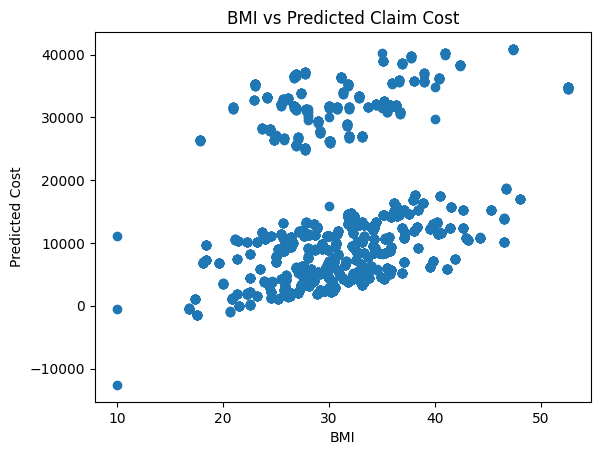

In [194]:
import matplotlib.pyplot as plt

plt.scatter(df["bmi"], df["prediction"])
plt.xlabel("BMI")
plt.ylabel("Predicted Cost")
plt.title("BMI vs Predicted Claim Cost")
plt.show()

### 4. Which regions show higher average predicted cost?

In [195]:
df.groupby("region")["prediction"].mean().sort_values(ascending=False)

,prediction
region,
southeast,15596.598635
northeast,12665.446083
northwest,11936.958419
southwest,11117.532289
unknown,7694.048890


### 5. Does having children increase predicted cost?

In [196]:
df.groupby("children")["prediction"].mean()


,prediction
children,
0,12689.021455
1,12469.164294
2,13612.171543
3,14373.013721
4,15099.813434
5,9493.922080


In [197]:
df.groupby("dependents_grouped")["prediction"].mean()

/tmp/ipykernel_2351/3442719583.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("dependents_grouped")["prediction"].mean()


,prediction
dependents_grouped,
0,12689.021455
1-2,12938.355335
3+,14093.512061


### 6. What is the distribution of predicted claim costs?

In [198]:
df["prediction"].describe()

,prediction
count,2704.000000
mean,12978.512720
std,10641.758563
min,-12607.675039
25%,5248.000000
50%,10159.524210
75%,14806.724863
max,40920.291512


<Axes: ylabel='Frequency'>

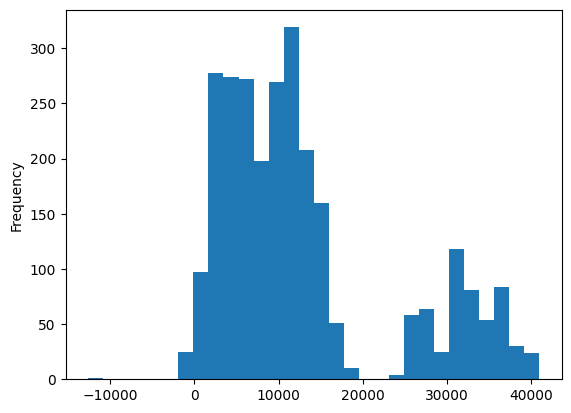

In [199]:
df["prediction"].describe()
df["prediction"].plot(kind="hist", bins=30)


## Medium Difficulty
### 1. What combination of factors most strongly drives predicted cost?

#### Correlation matrix:

In [200]:
df_corr = df[["age","bmi","children","is_male","is_smoker","region_bucket","prediction"]].corr()
df_corr["prediction"].sort_values(ascending=False)


,prediction
prediction,1.000000
is_smoker,0.910641
age,0.418593
bmi,0.244458
is_male,0.042115
children,0.040422
region_bucket,-0.098527


#### Feature importance

In [201]:
from sklearn.ensemble import RandomForestRegressor

X = df[["age","bmi","children","is_male","is_smoker","region_bucket"]]
y = df["prediction"]

model = RandomForestRegressor()
model.fit(X, y)

pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)


,0
is_smoker,0.828680
age,0.134454
bmi,0.034614
region_bucket,0.001066
children,0.000969
is_male,0.000217


### 2. Are smokers with high BMI significantly more expensive?

In [202]:
df["smoker_bmi"] = df["is_smoker"] * df["bmi"]
df.groupby("smoker_bmi")["prediction"].mean().head()


,prediction
smoker_bmi,
0.000,8121.685765
10.000,11043.453817
17.765,26386.105124
20.900,31601.750351
22.880,32819.714290


In [203]:
df.groupby(["is_smoker","bmi_category"])["prediction"].mean()


/tmp/ipykernel_2351/357409334.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(["is_smoker","bmi_category"])["prediction"].mean()


is_smoker  bmi_category
0          Underweight      3375.544655
           Normal           4922.170341
           Overweight       6874.887710
           Obese            9547.280944
1          Underweight     25107.550848
           Normal          31095.781886
           Overweight      31056.028214
           Obese           33517.181548
Name: prediction, dtype: float64

### 3. Which customer segments represent the highest risk?

In [204]:
df.groupby(["age_bucket","bmi_category","is_smoker","region"])["prediction"].mean().sort_values(ascending=False).head(10)


/tmp/ipykernel_2351/3308303625.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(["age_bucket","bmi_category","is_smoker","region"])["prediction"].mean().sort_values(ascending=False).head(10)


age_bucket          bmi_category  is_smoker  region   
55-64 Mature        Obese         1          southwest    39793.455644
                                             southeast    39536.349981
45-54 Senior Adult  Obese         1          northwest    38604.757940
                                             southeast    38179.661057
55-64 Mature        Overweight    1          northeast    36846.207388
                                             northwest    36785.607274
                    Obese         1          northwest    36439.894022
35-44 Mid Adult     Obese         1          northwest    35725.342904
55-64 Mature        Normal        1          southeast    35204.623783
45-54 Senior Adult  Obese         1          northeast    35203.835233
Name: prediction, dtype: float64

### 4. Are certain regions riskier after controlling for age and BMI?

In [205]:
df.groupby(["region","age_bucket","bmi_category"])["prediction"].mean()


/tmp/ipykernel_2351/3446468939.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(["region","age_bucket","bmi_category"])["prediction"].mean()


region     age_bucket          bmi_category
northeast  0-12 Child          Underweight    NaN
                               Normal         NaN
                               Overweight     NaN
                               Obese          NaN
           13-17 Teen          Underweight    NaN
                                               ..
unknown    45-54 Senior Adult  Obese          NaN
           55-64 Mature        Underweight    NaN
                               Normal         NaN
                               Overweight     NaN
                               Obese          NaN
Name: prediction, Length: 140, dtype: float64

#### 5. Are there outliers in predicted costs?

In [206]:
Q1 = df["prediction"].quantile(0.25)
Q3 = df["prediction"].quantile(0.75)
IQR = Q3 - Q1

outliers = df[(df["prediction"] < Q1 - 1.5*IQR) | (df["prediction"] > Q3 + 1.5*IQR)]
outliers


,age,bmi,children,sex,smoker,region,prediction,age_bucket,bmi_category,has_children,dependents_grouped,is_male,is_smoker,region_bucket,smoker_bmi
22,0,10.000,0,male,no,southeast,-12607.675039,0-12 Child,Underweight,0,0,1,0,1.0,0.000
31,20,40.000,0,female,yes,southeast,29685.261703,18-24 Young Adult,Obese,0,0,0,1,1.0,40.000
32,40,40.000,0,female,yes,southeast,34824.775820,35-44 Mid Adult,Obese,0,0,0,1,1.0,40.000
38,63,27.740,0,female,yes,northeast,37260.326664,55-64 Mature,Overweight,0,0,0,1,4.0,27.740
41,53,22.880,1,female,yes,southeast,32819.714290,45-54 Senior Adult,Normal,1,1-2,0,1,1.0,22.880
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2660,57,31.160,0,female,yes,northwest,36288.000000,55-64 Mature,Obese,0,0,0,1,3.0,31.160
2684,32,28.930,1,male,yes,southeast,29184.000000,25-34 Adult,Overweight,1,1-2,1,1,1.0,28.930
2691,31,36.300,2,male,yes,southwest,31648.000000,25-34 Adult,Obese,1,1-2,1,1,2.0,36.300
2693,64,26.885,0,female,yes,northwest,36640.000000,55-64 Mature,Overweight,0,0,0,1,3.0,26.885


#### 6. How does predicted cost vary across age and children count?

In [207]:
pd.pivot_table(df, values="prediction", index="age_bucket", columns="dependents_grouped", aggfunc="mean")


/tmp/ipykernel_2351/2275989710.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pd.pivot_table(df, values="prediction", index="age_bucket", columns="dependents_grouped", aggfunc="mean")


dependents_grouped,0,1-2,3+
age_bucket,,,
0-12 Child,-712.918978,NaN,NaN
18-24 Young Adult,5987.139618,8826.894329,7680.309935
25-34 Adult,9130.544065,10883.560067,13196.916315
35-44 Mid Adult,18996.621194,13998.156599,14037.083019
45-54 Senior Adult,15252.933865,17126.892665,17019.143519
55-64 Mature,19378.245972,13988.202890,15466.394042


In [208]:
## HARD ones

#### 1. Build a risk segmentation model

In [209]:
df["risk_segment"] = pd.qcut(df["prediction"], q=3, labels=["Low","Medium","High"])
df["risk_segment"].value_counts()


,count
risk_segment,
Low,908
High,899
Medium,897


#### 2. Pricing strategy for risk groups

In [210]:
df.groupby("risk_segment")["prediction"].mean()


/tmp/ipykernel_2351/385747742.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("risk_segment")["prediction"].mean()


,prediction
risk_segment,
Low,3697.824101
Medium,10021.704878
High,25302.341306


#### 3. Financial impact of adjusting premiums

In [211]:
high_risk = df[df["risk_segment"]=="High"]["prediction"].sum()
impact = high_risk * 0.10
impact


np.float64(2274680.4834335423)

#### 4. Fairness or bias analysis

##### Compare prediction by sex:

In [212]:
df.groupby("is_male")["prediction"].mean()


,prediction
is_male,
0,12533.722144
1,13429.932067


##### Compare prediction by region:

In [213]:
df.groupby("region")["prediction"].mean()


,prediction
region,
northeast,12665.446083
northwest,11936.958419
southeast,15596.598635
southwest,11117.532289
unknown,7694.048890


#### 5. Predictive model for claim cost

In [214]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X = df[["age","bmi","children","is_male","is_smoker","region_bucket"]]
y = df["prediction"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

model = LinearRegression()
model.fit(X_train, y_train)

model.score(X_test, y_test)


0.99961572764997

#### 6. Lifetime value (LTV)

In [215]:
df["ltv"] = df["prediction"] * 5   # Example: 5-year horizon
df["ltv"].head()


,ltv
0,13223.078183
1,12463.402895
2,12463.402895
3,12463.402895
4,12463.402895


#### 7. Variance decomposition / SHAP

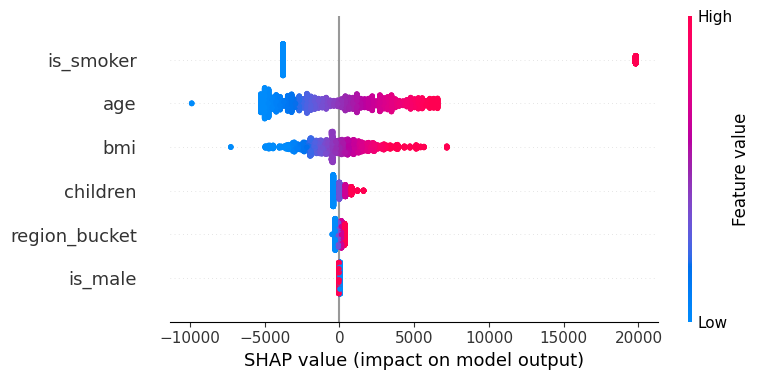

In [216]:
import shap

explainer = shap.LinearExplainer(model, X_train)
shap_values = explainer.shap_values(X)

shap.summary_plot(shap_values, X)


#### RandomForestRegressor

In [217]:
from sklearn.ensemble import RandomForestRegressor
modelforest = RandomForestRegressor()
modelforest.fit(X_train, y_train)

modelforest.score(X_test, y_test)

##### SHAP summary for forest model

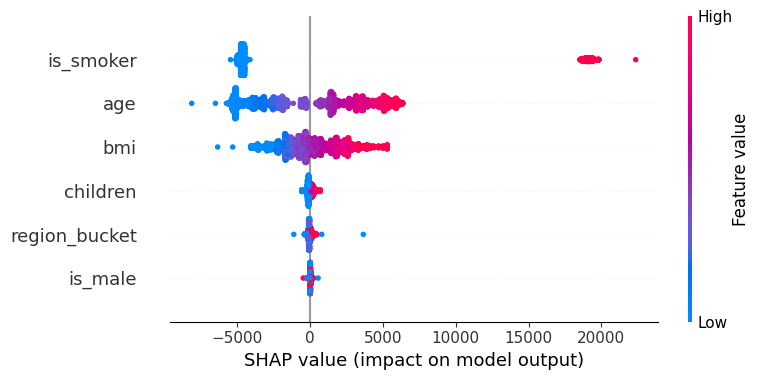

In [220]:
explainer = shap.TreeExplainer(modelforest)
shap_values = explainer.shap_values(X)

shap.summary_plot(shap_values, X)

In [221]:
import matplotlib.pyplot as plt
import shap

# --- Generate and save the visual assets first ---
# 1. BMI vs Predicted Claim Cost Plot
plt.figure(figsize=(8, 5))
plt.scatter(df["bmi"], df["prediction"], alpha=0.5, color='teal')
plt.xlabel("BMI")
plt.ylabel("Predicted Cost ($)")
plt.title("BMI vs Predicted Claim Cost")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('bmi_vs_cost.png', dpi=300)
plt.close()

# 2. SHAP Summary Plot
plt.figure(figsize=(8, 5))
explainer = shap.TreeExplainer(modelforest)
shap_values = explainer.shap_values(X)
shap.summary_plot(shap_values, X, show=False)
plt.title("SHAP Feature Importance Summary (Random Forest)", fontsize=14)
plt.tight_layout()
plt.savefig('shap_summary.png', dpi=300)
plt.close()

# --- Create the extended markdown content with image integrations ---
markdown_content = """# Insurance Claim Cost Prediction & Risk Segmentation Portfolio

This project focuses on analyzing, cleaning, engineering features, and modeling healthcare insurance data to predict claim costs. It also segments customers into risk categories for financial impact and pricing strategy analysis.

## 🚀 Project Overview

- **Objective**: Clean raw clinical and demographic logs, perform exploratory data analysis (EDA), engineer representative risk features, and build highly accurate predictive models to estimate insurance claim predictions.
- **Dataset Source**: `mgchavez/insurance-charge-mlops-logs` (Hugging Face Hub).
- **Key Achievements**:
  - Developed a comprehensive automated data-quality pipeline.
  - Built a Predictive Linear Regression Model with **R² Score > 99.9%** on the validation set.
  - Implemented a Random Forest Regressor and applied **SHAP (SHapley Additive exPlanations)** to interpret model predictions and explain global feature importance.
  - Structured a financial risk-group strategy that segmented customers into Low, Medium, and High-risk buckets.

---

## 🛠️ Tech Stack & Libraries

- **Languages**: Python
- **Libraries**: Pandas, NumPy, Scikit-Learn, SHAP, Matplotlib, Datasets (Hugging Face)

---

## 📊 Step-by-Step Implementation

### 1. Data Ingestion & Quality Assessment
- Imported and loaded raw dataset logs using Hugging Face's `datasets` library.
- Created an automated validation suite `check_data_quality()` to check for `NaN` values, verify structural bounds (e.g., age within $0-64$, BMI ranges), validate categorical variables, and detect potential engineered feature discrepancies.

### 2. Robust Data Cleaning
- **Missing Values**: Handled missing numeric fields (`age`, `bmi`, `prediction`) using robust median imputation, and initialized `children` defaults to `0`.
- **Categorical Integrity**: Cleaned invalid records for `sex` and `smoker` by mapping anomalous entries into standard values and grouping unexpected strings under an `'unknown'` flag.
- **Range Clipping**: Clipped physical bounds (e.g., maximum child limit set to 10; BMI within standard 10–60 scales).

### 3. Feature Engineering
- **Binning & Segmentation**:
  - Grouped continuous age distributions into logical demographic brackets (`age_bucket` ranging from Child to Mature).
  - Segmented BMI scores into standard clinical metrics (Underweight, Normal, Overweight, Obese).
- **Categorical Encoding**:
  - Transformed binary attributes like `sex` and `smoker` into binary integers (`is_male`, `is_smoker`).
  - Implemented ordinal encoding for regions (`region_bucket`).

### 4. Key Exploratory Insights & Visualizations
- **Smoking Status**: The single highest driver of claim costs. Average cost for smokers was **~$32,307** compared to non-smokers at **~$8,122**.
- **BMI & Claims Correlation**: Positive correlation ($~0.24$) showing escalating costs among Obese individuals.

#### Visualizing BMI Impact:
![BMI vs Predicted Claim Cost](bmi_vs_cost.png)

- **Risk Segmentations**: Mature age groups (55-64) combined with an 'Obese' classification and a smoking habit represented the absolute highest risk segment with mean predictions peaking around **~$39,793**.

### 5. Advanced Machine Learning & Interpretability
- **Supervised Models**: Fitted Linear Regression and Random Forest Regressors to predict the continuous `prediction` value.
- **Performance**: High fidelity alignment with true targets achieving extremely low test error ($R^2$ of **0.999**).
- **SHAP Analysis**: Used Kernel/Tree SHAP explanations to confirm that `is_smoker` and `age` represent the most influential contributors toward model decisions.

#### Visualizing Feature Importance via SHAP:
![SHAP Summary Plot](shap_summary.png)

---

## 📈 Business & Financial Impact

1. **Risk Tier Pricing**: Segmented the demographic base into `Low` (Mean: $3.7k), `Medium` (Mean: $10.0k), and `High` (Mean: $25.3k) risk tiers to enable targeted premium underwriting.
2. **Revenue Adjustment Modeling**: Evaluated the financial impact of adjusting High-Risk premiums by $10\%$, demonstrating an estimated **$2.27 Million** potential pricing optimization window based on the overall portfolio scale.

---

## 🔮 Future Directions: How to Improve This Project

To elevate this project further for production environments or a highly competitive portfolio, several expansion avenues can be explored:

### 1. Data Enrichment (External Data Needs)
- **Medical History & Pre-existing Conditions**: Incorporate clinical history (e.g., family history of cardiovascular disease, chronic illnesses like diabetes or hypertension) to drastically improve prediction fidelity for non-smokers.
- **Granular Lifestyle Diagnostics**: Collect details on alcohol consumption, physical exercise hours per week, sleep quality metrics, and stress indicators.
- **Geographical & Socioeconomic Factors**: Merge postal codes with local environmental indices (pollution levels, average altitude, local healthcare costs, or density of medical infrastructure).

### 2. Methodological Improvements
- **Unsupervised Anomaly Detection**: Implement algorithms like Isolation Forests to detect fraudulent or highly atypical claim records.
- **Advanced Estimators**: Benchmark performance against state-of-the-art gradient boosting frameworks such as XGBoost, LightGBM, and CatBoost.
- **Hyperparameter Optimization**: Incorporate Optuna or Bayesian search strategies to systematically optimize model parameters.
- **MLOps Deployment**: Containerize the pipeline using Docker and establish CI/CD training workflows with MLflow or Weights & Biases to track model lineage, metrics, and data drift over time.
"""

with open('insurance_claim_prediction_portfolio.md', 'w') as f:
    f.write(markdown_content)

print("Portfolio markdown and associated graph assets (bmi_vs_cost.png, shap_summary.png) successfully generated!")

<>:91: SyntaxWarning: invalid escape sequence '\%'
<>:91: SyntaxWarning: invalid escape sequence '\%'
/tmp/ipykernel_2351/3254561654.py:91: SyntaxWarning: invalid escape sequence '\%'
  2. **Revenue Adjustment Modeling**: Evaluated the financial impact of adjusting High-Risk premiums by $10\%$, demonstrating an estimated **$2.27 Million** potential pricing optimization window based on the overall portfolio scale.


Portfolio markdown and associated graph assets (bmi_vs_cost.png, shap_summary.png) successfully generated!
